# 00, What data we have, and what it can support

**Place in the argument.** The starting point. Before interpreting any variant, this notebook
separates the questions the data can answer from those that need a modality that does not
exist.

**Main output.** Measured sequencing QC and an inventory of available and missing modalities.
It does not prioritise genes.

> **Sanitised output.** No local path, no sample identifier, no coordinate.

## The question

**Are the data fit for purpose, and which questions can they reach?**

Two different questions. The first is answered by QC of the FASTQ. The second, by an inventory
of what exists and what does not.

**Scope.** The data are **one genome**. One blood sample,
sequenced on one flowcell across four lanes (eight FASTQ files, one VCF column). The lanes are
technical partitions, not people or biological replicates. There are no parents, no RNA and no
protein data.

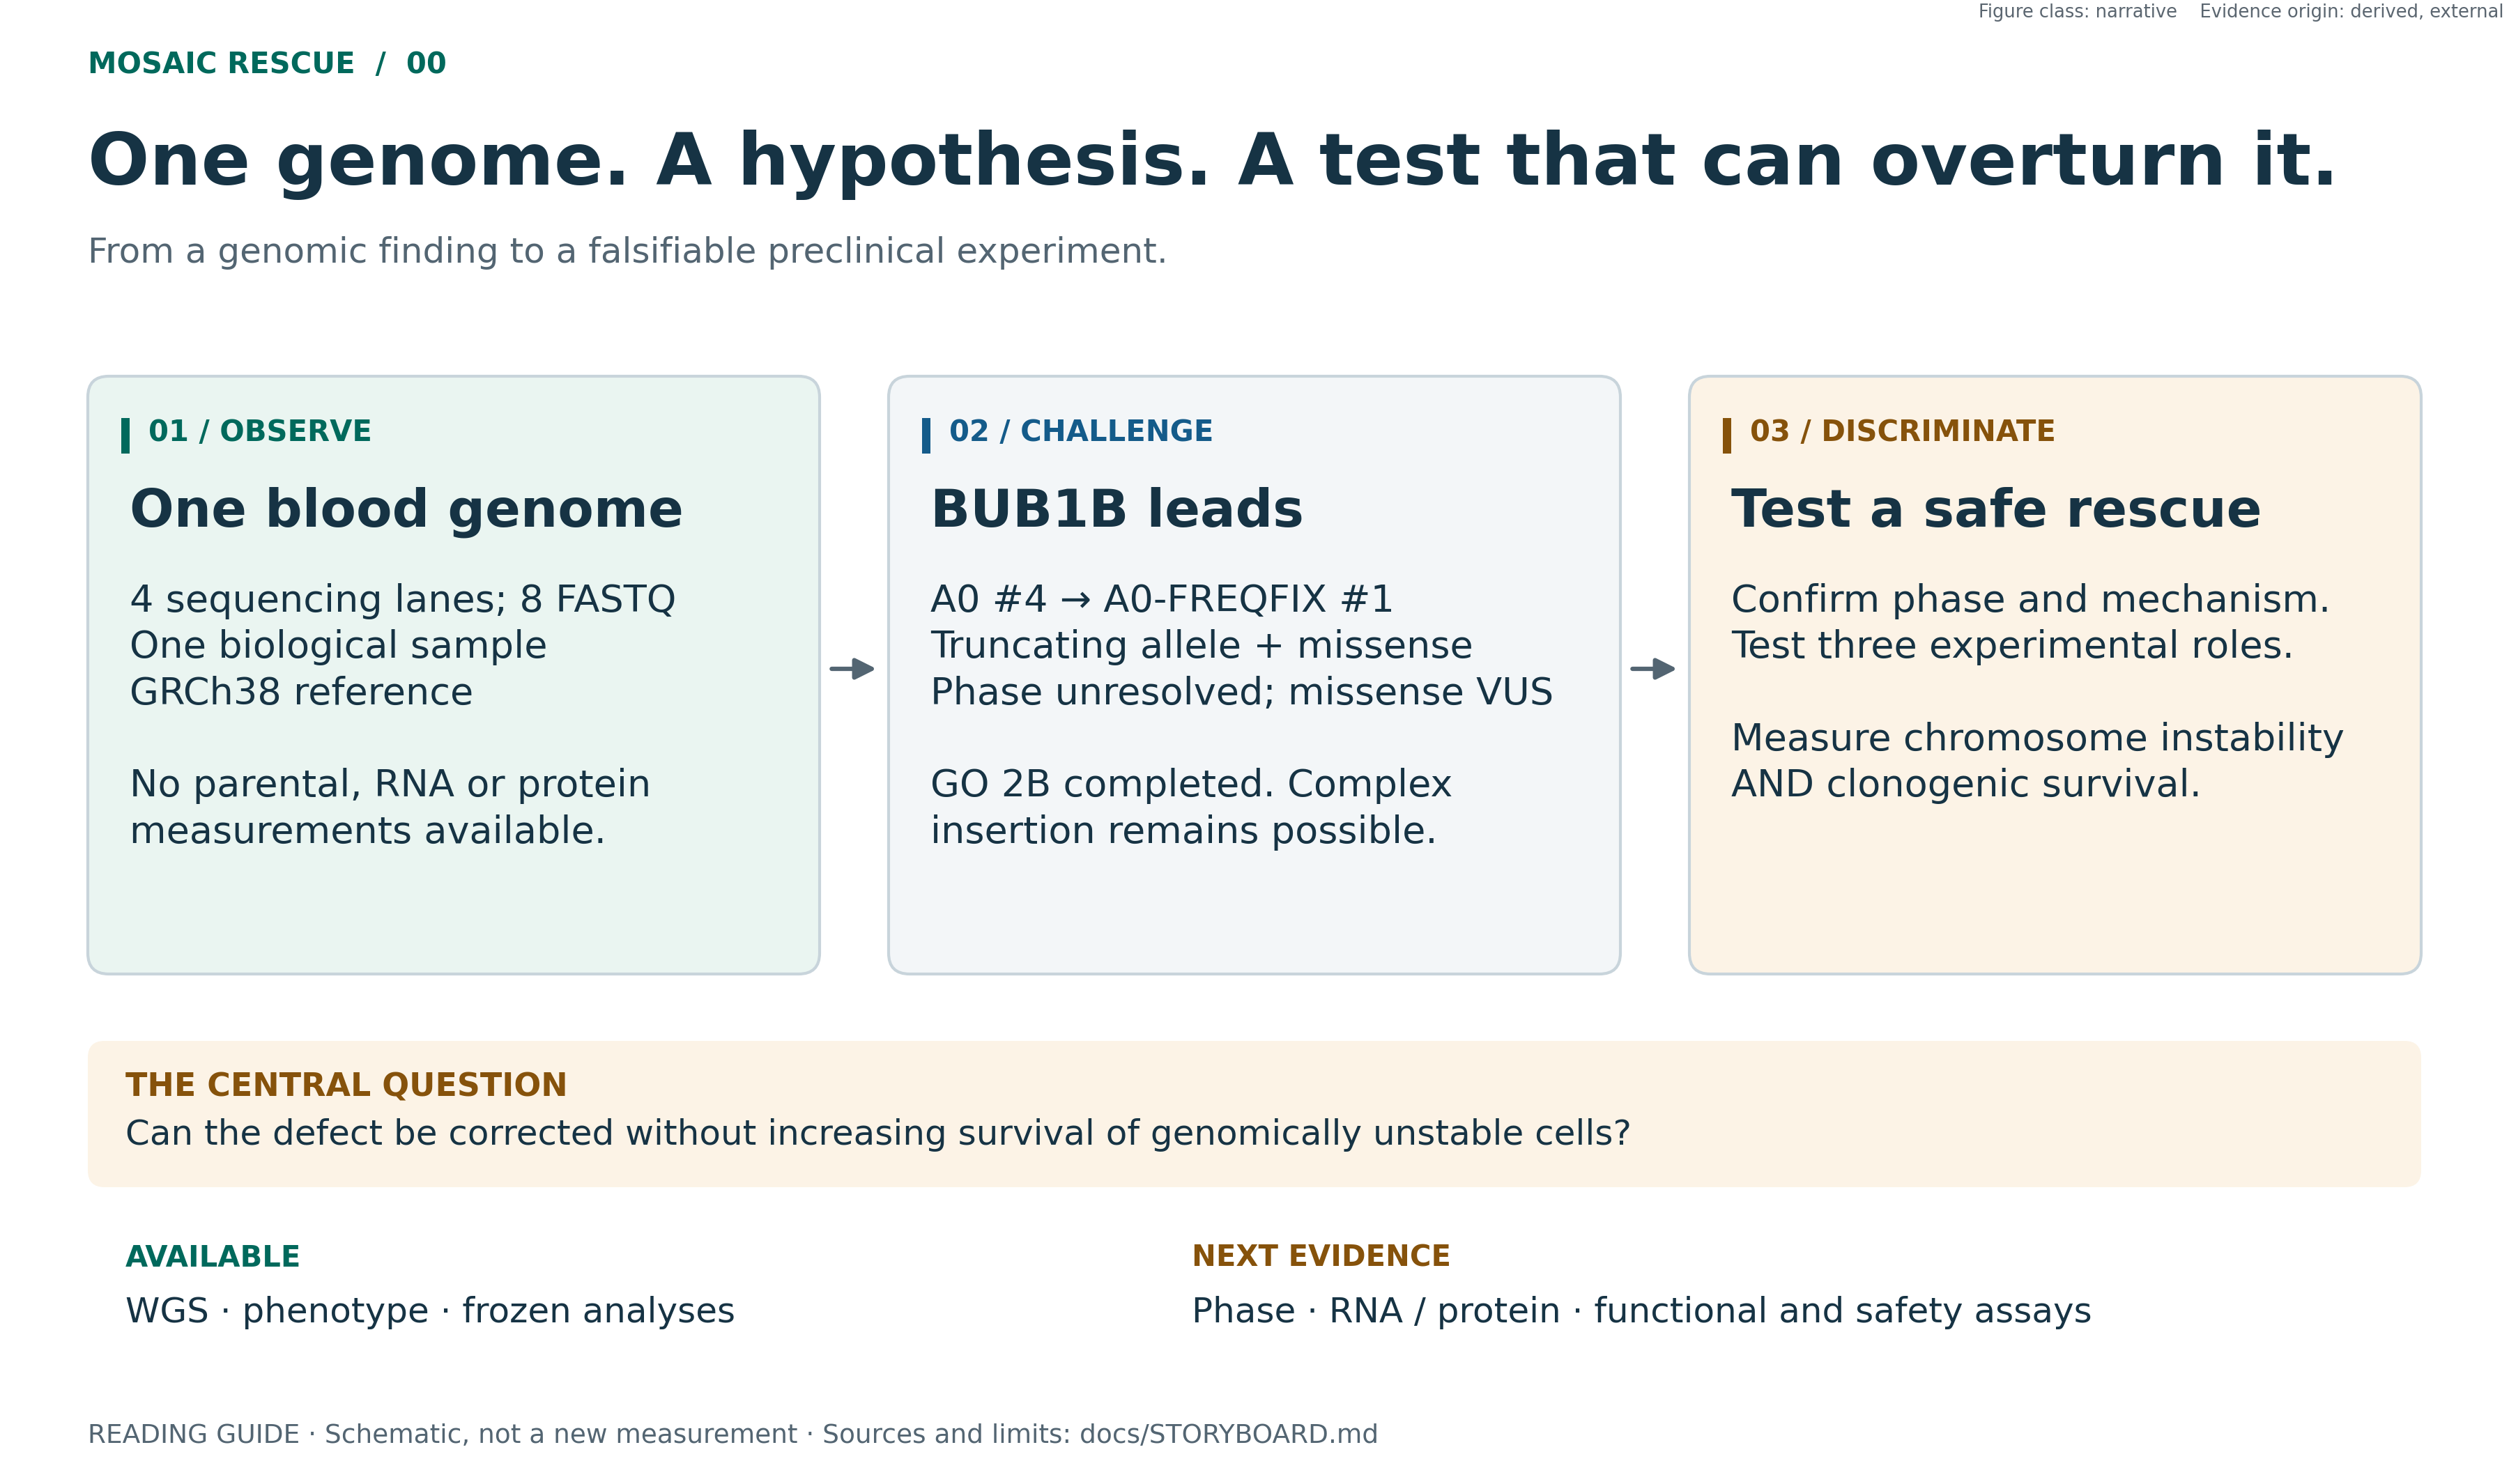

**`NARRATIVE`, DERIVED / EXTERNAL.** One biological sample, four technical lanes. The full BAM now exists; the QC below keeps its original L001 scope. Reviewed figure, embedded without re-running the original analysis, [sources and limits](../docs/STORYBOARD.md), [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("Environment ready. Figures render inline, each with a provenance caption.")

Environment ready. Figures render inline, each with a provenance caption.


In [2]:
fl.labels("Reading", "How far it reaches")

## Sequencing QC, computed rather than quoted

A reproducible subsample of L001 R1. The reads are traversed once and per-cycle statistics are
accumulated; nothing comes from the brief.

In [3]:
from src.figures import fig00_qc as F
from src.paths import get, patient_vcf

fq1 = get("patient", "fastq_l001_r1")
N = F.N_DEFAULT                  # reproducible subsample: the statistics are aggregates

# One pass over the FASTQ, the same one the publication figure uses. The notebook and the
# figure used to have two implementations of the scan; they could diverge, and a figure that
# does not reproduce what its notebook prints cannot be trusted.
D = F.scan(fq1, n_reads=N)

n, CYC = D["n_reads"], D["cycles"]
gcarr = D["gc"]
median_readq = float(np.median(D["read_mean_q"]))
non_top_first, non_top_last = float(D["non_top"][0]), float(D["non_top"][-1])

print(f"  reads sampled          : {n:,}")
print(f"  read length            : {CYC} bp ,  distinct values: {len(D['lengths'])}")
print(f"  quality bins           : {len(D['levels'])} to "
      + ", ".join("Q" + str(v) for v in D["levels"]))
print(f"  outside the top bin    : {non_top_first:.2f} % at cycle 1 to "
      f"{non_top_last:.2f} % at cycle {CYC}")
print(f"  mean GC per read       : {gcarr.mean():.1f} %  (sd {gcarr.std():.1f})")
print(f"  mean quality per read  : median {median_readq:.1f} ,  "
      f"{100 * float((D['read_mean_q'] < 30).mean()):.1f} % below Q30")
print(f"  bases >= Q30           : {D['q30_pct']:.1f} %")

  reads sampled          : 300,000
  read length            : 149 bp ,  distinct values: 1
  quality bins           : 4 to Q2, Q11, Q25, Q37
  outside the top bin    : 4.52 % at cycle 1 to 13.29 % at cycle 149
  mean GC per read       : 41.3 %  (sd 10.2)
  mean quality per read  : median 36.5 ,  3.0 % below Q30
  bases >= Q30           : 92.9 %


### Scientific figure 1. per-cycle sequencing QC

The four panels any real QC report looks at, **computed here**: quality by cycle with its
spread, GC per read against the theoretical distribution, mean quality per read, and base
composition by cycle.

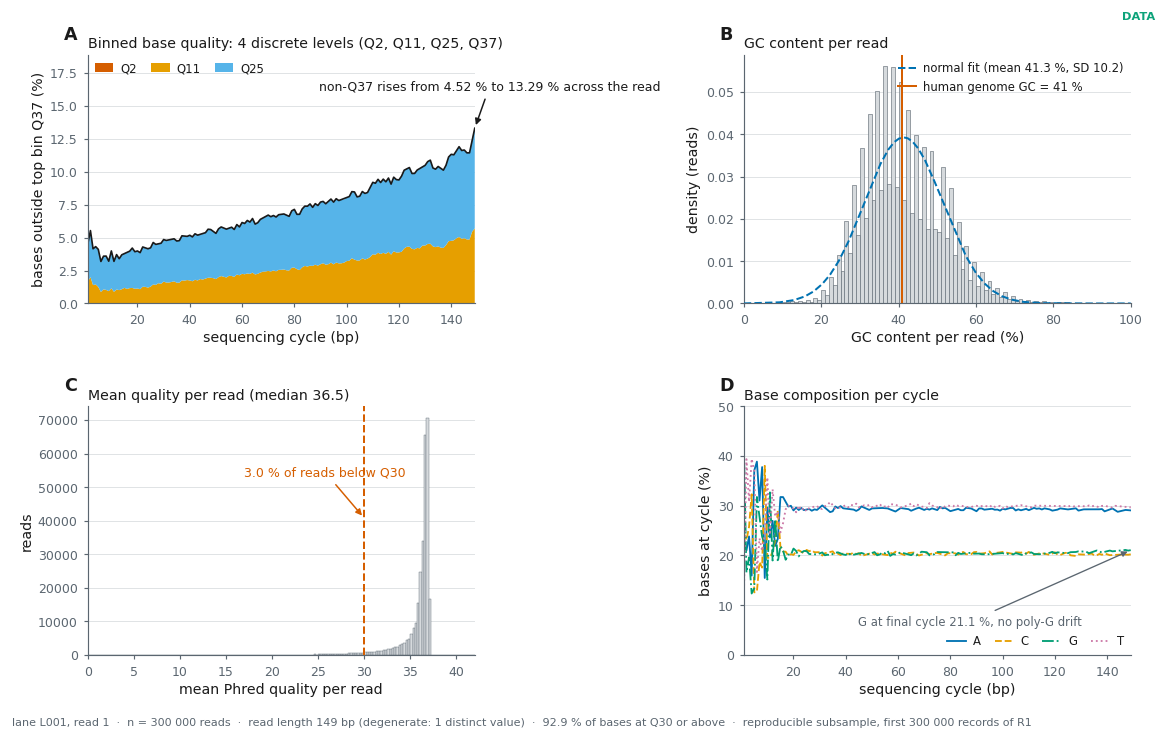

**Figure 1: Sequencing QC of lane L001.** EXP-001; class `DATA` (scientific figure); evidence origin MEASURED.

*Reading:* the real degradation along the read. This sequencer reports binned qualities in four values (Q2, Q11, Q25, Q37), so what is informative is the mass that leaves the top bin: from 4.52 % at cycle 1 to 13.29 % at cycle 149. Also: GC per read centred on 41.3 % against 41 % for the human genome, a median per-read quality of 36.5, and stable base composition with no poly-G drift at the end of the read.

*How far it reaches:* that the data are sufficient. QC says they are fit, not that they reach the open questions. It also says nothing about library type: PCR-free and DNA Prep share an adapter, and that remains unanswered.

<sub>Data: reproducible subsample of 300,000 reads from L001 R1. Library: matplotlib. Provenance: figures/pub/fig00_fastq_qc.svg + .png 300 dpi.</sub>

In [4]:
fig = F.build(D)
fl.pub(fig, "Figure 1: Sequencing QC of lane L001", "EXP-001", "MEASURED", "DATA",
       f"the real degradation along the read. This sequencer reports binned qualities in four "
       f"values (Q2, Q11, Q25, Q37), so what is informative is the mass that leaves the top bin: "
       f"from {non_top_first:.2f} % at cycle 1 to {non_top_last:.2f} % at cycle {CYC}. Also: GC "
       f"per read centred on {gcarr.mean():.1f} % against 41 % for the human genome, a median "
       f"per-read quality of {median_readq:.1f}, and stable base composition with no poly-G "
       f"drift at the end of the read.",
       "that the data are sufficient. QC says they are fit, not that they reach the open "
       "questions. It also says nothing about library type: PCR-free and DNA Prep share an "
       "adapter, and that remains unanswered.",
       source=f"reproducible subsample of {n:,} reads from L001 R1",
       lib="matplotlib", slug="fig00_fastq_qc")

## Modality inventory: metadata, not a scientific object

This is **not** a scientific figure, and it is labelled as such. It is the boundary of what the
project can claim, and it is checked on disk, not declared.

In [5]:
import glob
from IPython.display import Markdown, display

def size_gb(p):
    return os.path.getsize(p) / 2**30 if p and os.path.exists(p) else None

vcf = patient_vcf()
lanes = sorted(glob.glob(os.path.dirname(fq1) + "/*_L00[2-4]_R[12]_*.fastq.gz"))
bam = glob.glob("work/align/*.bam")
MOD = [
    ("WGS VCF",                        os.path.exists(vcf),  f"{size_gb(vcf):.2f} GB"),
    ("FASTQ, lane L001 (R1)",          os.path.exists(fq1),  f"{size_gb(fq1):.1f} GB"),
    ("FASTQ, lanes L002 to L004",      len(lanes) > 0,       f"{len(lanes)} files on disk"),
    ("Full-depth alignment (BAM)",     len(bam) > 0,         "rebuilt in GO 2A from all four lanes"),
    ("Parental genotypes",             False, "not supplied: phase cannot be resolved"),
    ("RNA-seq",                        False, "does not exist: splicing cannot be measured"),
    ("Long reads",                     False, "do not exist: complex insertions cannot be excluded"),
    ("Protein / functional assay",     False, "does not exist: missense function cannot be measured"),
    ("Single-cell data",               False, "does not exist: mosaic fraction cannot be estimated"),
    ("Tumour tissue",                  False, "not supplied"),
    ("Prior karyotype / array",        False, "not supplied"),
    ("Contemporaneous blood count",    False, "requested, no answer"),
    ("HPO phenotype",                  os.path.exists("config/phenotype_v2.yaml"), "7 + 1 terms"),
]
md = ["| Modality | Available | Note |", "|---|:---:|---|"]
md += [f"| {name} | {'yes' if present else '**no**'} | {note} |" for name, present, note in MOD]
display(Markdown("\n".join(md)))

| Modality | Available | Note |
|---|:---:|---|
| WGS VCF | yes | 0.29 GB |
| FASTQ, lane L001 (R1) | yes | 9.7 GB |
| FASTQ, lanes L002 to L004 | yes | 6 files on disk |
| Full-depth alignment (BAM) | yes | rebuilt in GO 2A from all four lanes |
| Parental genotypes | **no** | not supplied: phase cannot be resolved |
| RNA-seq | **no** | does not exist: splicing cannot be measured |
| Long reads | **no** | do not exist: complex insertions cannot be excluded |
| Protein / functional assay | **no** | does not exist: missense function cannot be measured |
| Single-cell data | **no** | does not exist: mosaic fraction cannot be estimated |
| Tumour tissue | **no** | not supplied |
| Prior karyotype / array | **no** | not supplied |
| Contemporaneous blood count | **no** | requested, no answer |
| HPO phenotype | yes | 7 + 1 terms |

## Decision

| | |
|---|---|
| **The data are fit** | invariant read length, GC in range, high Q30, no poly-G drift |
| **They are not sufficient** | the four open questions of the project (phase, missense function, safe rescue, generality of the method) each need a modality that is missing here |

### What this notebook does not show

That the missing modalities will arrive, or that the data present reach the open questions.
**And a negative can never be closed with L001 alone**: a single lane at ~13× is a pilot.

### Falsifier

If any modality marked missing appears, the notebook must be re-run. It is built for that: **no
value is typed in by hand**.

### Next

`01_TRACK1_GENOME_WIDE`.

In [6]:
fl.summary()

  figures: 1, scientific: 1, narrative/synthesis: 0

  class         evidence              library             title
  ------------------------------------------------------------------------------------------------
  DATA          MEASURED              matplotlib          Figure 1: Sequencing QC of lane L001
